In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../'))
sys.path.append(base_path)

import tensorflow as tf
from tensorflow.keras.callbacks import TensorBoard

import numpy as np
from tqdm import tqdm
import datetime

from data_loaders.data_loader_complete import DataLoaderComplete
import project_images_loader as pil

import discriminator as Discriminator
import generator as Generator
import feature_extractor as feature_extractor

import utils.functions as fc
import utils.util_deep_learning as udl
import utils.util as util
import utils.visualization as vis

tf.keras.backend.set_image_data_format("channels_first")



2024-03-31 05:39:22.131126: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-03-31 05:39:22.176879: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-03-31 05:39:22.176937: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-03-31 05:39:22.178277: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-03-31 05:39:22.190536: I tensorflow/core/platform/cpu_feature_guar

## Visualize data

In [2]:
# %matplotlib widget

# data_train = DataLoader(batch_size=3, image_size=(193,229,193), shuffle=False, channels_first=True, image_sufix=pil.INAME_PREPROCESSED, nb_patients=-1)
# fc.imgshow_3D("", data_train[0][0][0,0])

### Validation visualization

In [3]:
def show_generated_image(id, G, img_size, current_plane=116):
    def fast_resieze(img, img_size):
        return img[:img_size[0], :img_size[1], :img_size[2]]
    
    img_hunt3 = fast_resieze(pil.load_preprocessed_image(3, id, absolute=True)[0], img_size)
    img_hunt4 = fast_resieze(pil.load_preprocessed_image(4, id, absolute=True)[0], img_size)

    img_gen_h4 = G(np.expand_dims(np.expand_dims(img_hunt3, axis=0), axis=0), training=False)
    img_gen_h4 = img_gen_h4[0,0].numpy()
    img_gen_h4[img_gen_h4 < 0] = 0
    img_gen_h4 = img_gen_h4 / np.max(img_gen_h4)

    vis.shows_3_images(img_hunt3, img_hunt4, img_gen_h4, current_plane=current_plane)



### Loss functions

In [4]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=False)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    total_loss = (real_loss + fake_loss)/2
    return total_loss

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)


In [5]:
# @tf.function
# def val_step(model, x_images, y_true, masks, class_centers, epoch):
#     y_pred, x_feat, x_gap = model(x_images, training=False)
#     x_weights = model.layers[-1].weights[0]
#     loss, loss_ce, loss_cskl, loss_cl, loss_cskl_mask = combined_loss(y_true, y_pred, x_feat, x_weights, masks, x_gap, class_centers, epoch)
#     return y_pred, loss, loss_ce, loss_cskl, loss_cl, loss_cskl_mask

@tf.function
def train_step(G, D, Fe, h3_batch, h4_batch, g_optimizer, d_optimizer):
    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        h4_fake = G(h3_batch, training=True)

        # real_output = D([h3_batch, h4_batch], training=True)
        # fake_output = D([h3_batch, h4_fake], training=True)

        real_output = D(h4_batch, training=True)
        fake_output = D(h4_fake, training=True)

        _gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

        feature_fake_y_list = Fe(h4_fake, training=False)
        feature_y_list = Fe(h4_batch, training=False)

        l1_loss = tf.reduce_mean(tf.abs(h4_batch - h4_fake))
        percetual_loss = tf.reduce_mean(tf.abs(feature_y_list - feature_fake_y_list))

        # cor_loss = correlation_loss(y_batch, y_batch_fake)

        gen_loss = _gen_loss + 25.0 * l1_loss + 25.0 * percetual_loss

    gradients_of_generator = gen_tape.gradient(gen_loss, G.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, D.trainable_variables)

    g_optimizer.apply_gradients(zip(gradients_of_generator, G.trainable_variables))
    d_optimizer.apply_gradients(zip(gradients_of_discriminator, D.trainable_variables))

    return gen_loss, disc_loss, l1_loss, percetual_loss



In [6]:
# data_train = DataLoader(f"{pil.get_base_folder()}data/data_reduced/train", batch_size=1, image_size=(200, 240, 240), shuffle=True, channels_first=False)
# data = data_train[0]

# # dloader = DataLoader(root_folder=f"data_test", batch_size=3, image_size=(200, 240, 240))
# fc.imgshow_3D(f"Original", data[0][0,...,0], current_plane=150)

### Training

Instructions for updating:
Call initializer instance with the dtype argument instead of passing it to the constructor


2024-03-31 05:39:26.339132: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1929] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 38374 MB memory:  -> device: 0, name: NVIDIA A100-PCIE-40GB, pci bus id: 0000:49:00.0, compute capability: 8.0



Epoch 1/50


2024-03-31 05:39:28.261439: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
2024-03-31 05:39:28.345584: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-03-31 05:39:29.068440: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory


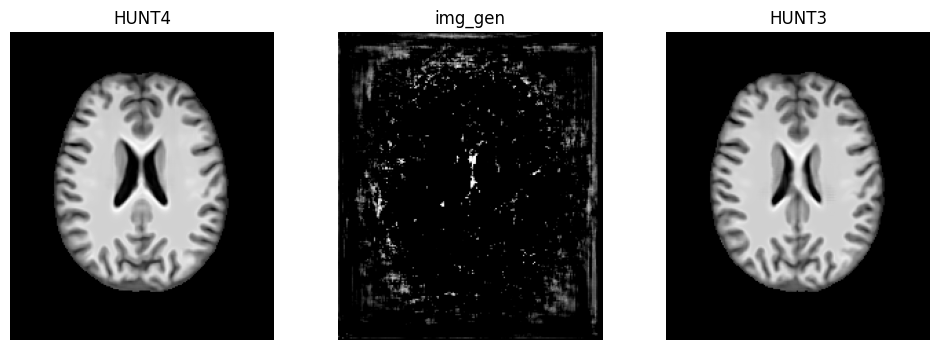

Initializing...:   0%|          | 0/300 [00:00<?, ?it/s]2024-03-31 05:40:18.287780: W external/local_tsl/tsl/framework/bfc_allocator.cc:485] Allocator (GPU_0_bfc) ran out of memory trying to allocate 504.00MiB (rounded to 528482304)requested by op gradient_tape/model_3/max_pooling3d_4/MaxPool3D/MaxPool3DGrad
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
2024-03-31 05:40:18.287827: I external/local_tsl/tsl/framework/bfc_allocator.cc:1039] BFCAllocator dump for GPU_0_bfc
2024-03-31 05:40:18.287836: I external/local_tsl/tsl/framework/bfc_allocator.cc:1046] Bin (256): 	Total Chunks: 235, Chunks in use: 233. 58.8KiB allocated for chunks. 58.2KiB in use in bin. 19.8KiB client-requested in use in bin.
2024-03-31 05:40:18.287841: I external/local_tsl/tsl/framework/bfc_allocator.cc:1046] Bin (512): 	Total Chunks: 129, Chunks in use: 129.

ResourceExhaustedError: Graph execution error:

Detected at node gradient_tape/model_3/max_pooling3d_4/MaxPool3D/MaxPool3DGrad defined at (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main

  File "<frozen runpy>", line 88, in _run_code

  File "/cluster/home/agustinc/miniconda3/envs/s4/lib/python3.11/site-packages/ipykernel_launcher.py", line 18, in <module>

  File "/cluster/home/agustinc/miniconda3/envs/s4/lib/python3.11/site-packages/traitlets/config/application.py", line 1075, in launch_instance

  File "/cluster/home/agustinc/miniconda3/envs/s4/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 739, in start

  File "/cluster/home/agustinc/miniconda3/envs/s4/lib/python3.11/site-packages/tornado/platform/asyncio.py", line 205, in start

  File "/cluster/home/agustinc/miniconda3/envs/s4/lib/python3.11/asyncio/base_events.py", line 607, in run_forever

  File "/cluster/home/agustinc/miniconda3/envs/s4/lib/python3.11/asyncio/base_events.py", li

In [7]:

def train(num_epochs, batch_size):
    # input_shape = (193,229,193)
    input_shape = (192,224,192)
    # input_shape = (64,64,64)
    current_plane = 116

    # ---- Models
    D = Discriminator.create_discriminator_model(input_shape)
    G = Generator.create_generator_model(input_shape)
    Fe = feature_extractor.create_features_extractor((1,)+input_shape, f"{current_path}/models/genesis_model/Genesis_Chest_CT.h5")
    
    # Freeze features extractor layers
    udl.freeze_layers(Fe, 0)

    # optimizers
    inital_lr = 1e-4
    g_optimizer = tf.keras.optimizers.Adam(inital_lr)
    d_optimizer = tf.keras.optimizers.Adam(inital_lr)

    # ---- Data
    server = True
    data_train = DataLoaderComplete(image_sufix=pil.INAME_PREPROCESSED,
                                    batch_size=batch_size, 
                                    image_size=input_shape, 
                                    channels_first=True,
                                    shuffle=True, 
                                    nb_patients=300, 
                                    shuffle_before_selecting=False, 
                                    server=server)
    # visualization
    nb_loss = 4
    acum_loss_train = udl.AcumulativeMetrics(nb_metrics = nb_loss)
    # tensorboard_callback = TensorBoard(log_dir=f"{current_path}/models/logs")

    log_dir=f"{current_path}/models/logs/"
    summary_writer = tf.summary.create_file_writer(
    log_dir + "fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))
    # %load_ext tensorboard
    # %tensorboard --logdir {log_dir}

    # ---- checkpoint
    checkpoint_dir = f"{current_path}/models/training_checkpoints/"
    checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")
    checkpoint = tf.train.Checkpoint(g_optimizer=g_optimizer,
                                     d_optimizer=d_optimizer,
                                    G=G,
                                    D=D)
    # restore checkpoint
    checkpoint.restore(tf.train.latest_checkpoint(checkpoint_dir))

    for epoch in range(0,num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")
        
        # visualize images
        show_generated_image("08202", G, input_shape, current_plane=current_plane)

        # ---- Train
        acum_loss_train.reset()
        progress_bar = tqdm(total=len(data_train), desc=f'Initializing...')
        for step, (h3_batch, h4_batch) in enumerate(data_train):
  
            gen_loss, disc_loss, l1_loss, percetual_loss = train_step(G, D, Fe, h3_batch, h4_batch, g_optimizer, d_optimizer)
            acum_loss_train.update((gen_loss, disc_loss, l1_loss, percetual_loss))
            losses_text = acum_loss_train.get_progress_bar_text(['gen_loss', 'disc_loss', 'l1_loss', 'percetual_loss'])

            progress_bar.set_description(desc=losses_text)
            progress_bar.update(1)
        del progress_bar

        # ---- Check points
        if  epoch > 0 and epoch % 2 == 0:
            checkpoint.save(file_prefix=checkpoint_prefix)
        
        # ---- Learning rate
        if epoch > 44 and epoch % 22 == 0:
            inital_lr *= 0.5
            g_optimizer.learning_rate = inital_lr
            d_optimizer.learning_rate = inital_lr

        # ---- tensorboard
        loss_mean = acum_loss_train.get_mean()
        with summary_writer.as_default():
            tf.summary.scalar('gen_loss', loss_mean[0], step=epoch)
            tf.summary.scalar('disc_loss', loss_mean[1], step=epoch)
            tf.summary.scalar('l1_loss', loss_mean[2], step=epoch)
            tf.summary.scalar('percetual_loss', loss_mean[3], step=epoch)


train(num_epochs=50, batch_size=1)

In [ ]:
# Sim: 0.00000 	 gen_loss: 0.93415 	 disc_loss: 1.11709: 100%|██████████| 8/8 [00:14<00:00,  1.86s/it]
# Sim: 0.00000 	 gen_loss: 1.22538 	 disc_loss: 1.64933: 100%|██████████| 8/8 [00:14<00:00,  1.86s/it]